# TMDB Movie Data Analysis using Pandas and APIs

**By:** Molo Munyansanga

---

## Project Overview

This project challenges you to build a movie data analysis pipeline using Python and Pandas. You will fetch movie-related data from an API, clean and transform the dataset, and implement key performance indicators (KPIs).

This is not a group project, meaning you will design the workflow, structure the analysis, and implement the required calculations independently.

---

## Project Objectives

- **API Data Extraction:** Fetch movie data from a movie database API
- **Data Cleaning & Transformation:** Process and structure the data for analysis
- **Exploratory Data Analysis (EDA):** Perform an initial exploration to understand trends
- **Advanced Filtering & Ranking:** Identify the best and worst movies based on financial and popularity metrics
- **Franchise & Director Analysis:** Assess how franchises and directors perform over time
- **Visualization & Insights:** Present key findings using visualizations

---

In [1]:
# Import the libraries that we will use throughout the project
import os
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv

## Project Steps

### Step 1: Fetch Movie Data from API

- Choose a movie database API (e.g., TMDb)
- Fetch movies with the following IDs:

```python
movie_id = [
    0, 299534, 19995, 140607, 299536, 597, 135397,
    420818, 24428, 168259, 99861, 284054, 12445,
    181808, 330457, 351286, 109445, 321612, 260513
]
```

- Store the data as a Pandas DataFrame

> **NB:** Read the API documentation to understand the nature of the data and how it's organized.

---

In [2]:
# Getting the api token stored in our .env file
load_dotenv()
TOKEN = os.getenv("API_READ_ACCESS_TOKEN")
# incase the token is missing:
if not TOKEN:
    raise ValueError("API_READ_ACCESS_TOKEN is missing from your .env file.")

# Collection of movie ids whose data we will use for the project
movie_collection = [
    0, 299534, 19995, 140607, 299536, 597, 135397,
    420818, 24428, 168259, 99861, 284054, 12445,
    181808, 330457, 351286, 109445, 321612, 260513
]

movies = []

# Loop through the api url using each "movie id"
for movie_id in movie_collection:
    url = f"https://api.themoviedb.org/3/movie/{movie_id}?language=en-US&append_to_response=credits"
    try:
        # The header where the token is applied
        headers = {
            "accept": "application/json",
            "Authorization": f"Bearer {TOKEN}"
        }
        # the response from the api
        response = requests.get(url, headers=headers)
        # convert the response to json
        movie_data = response.json()
        # save the data to our list
        movies.append(response.json())
        print(f"Fetched: {movie_data.get('title', movie_id)}")
        
    except requests.exceptions.HTTPError as error:
        print(f"Could not fetch movie ID {movie_id}: {error}")

    except requests.exceptions.RequestException as error:
        print(f"Request failed for movie ID {movie_id}: {error}")

# Convert the list of dictionaries into a DataFrame
fetched_data = pd.DataFrame(movies)

Fetched: 0
Fetched: Avengers: Endgame
Fetched: Avatar
Fetched: Star Wars: The Force Awakens
Fetched: Avengers: Infinity War
Fetched: Titanic
Fetched: Jurassic World
Fetched: The Lion King
Fetched: The Avengers
Fetched: Furious 7
Fetched: Avengers: Age of Ultron
Fetched: Black Panther
Fetched: Harry Potter and the Deathly Hallows: Part 2
Fetched: Star Wars: The Last Jedi
Fetched: Frozen II
Fetched: Jurassic World: Fallen Kingdom
Fetched: Frozen
Fetched: Beauty and the Beast
Fetched: Incredibles 2


In [3]:
# Drop the first row, since the API failed to retrieve it (movie id = 0)
df = fetched_data.drop(fetched_data.index[0]).reset_index(drop=True)

In [4]:
df.head()

,success,status_code,status_message,adult,backdrop_path,belongs_to_collection,budget,genres,homepage,id,...,runtime,softcore,spoken_languages,status,tagline,title,video,vote_average,vote_count,credits
0,NaN,NaN,NaN,False,/7RyHsO4yDXtBv1zUU3mTpHeQ0d5.jpg,"{'id': 86311, 'name': 'The Avengers Collection...",356000000.0,"[{'id': 12, 'name': 'Adventure'}, {'id': 878, ...",https://www.marvel.com/movies/avengers-endgame,299534.0,...,181.0,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Avenge the fallen.,Avengers: Endgame,False,8.246,28993.0,"{'cast': [{'adult': False, 'gender': 2, 'id': ..."
1,NaN,NaN,NaN,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,"{'id': 87096, 'name': 'Avatar Collection', 'po...",237000000.0,"[{'id': 878, 'name': 'Science Fiction'}, {'id'...",https://www.avatar.com/movies/avatar,19995.0,...,162.0,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Enter the world of Pandora.,Avatar,False,7.610,34832.0,"{'cast': [{'adult': False, 'gender': 2, 'id': ..."
2,NaN,NaN,NaN,False,/8BTsTfln4jlQrLXUBquXJ0ASQy9.jpg,"{'id': 10, 'name': 'Star Wars Collection', 'po...",245000000.0,"[{'id': 12, 'name': 'Adventure'}, {'id': 28, '...",http://www.starwars.com/films/star-wars-episod...,140607.0,...,136.0,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Every generation has a story.,Star Wars: The Force Awakens,False,7.240,21006.0,"{'cast': [{'adult': False, 'gender': 1, 'id': ..."
3,NaN,NaN,NaN,False,/mDfJG3LC3Dqb67AZ52x3Z0jU0uB.jpg,"{'id': 86311, 'name': 'The Avengers Collection...",300000000.0,"[{'id': 12, 'name': 'Adventure'}, {'id': 28, '...",https://www.marvel.com/movies/avengers-infinit...,299536.0,...,149.0,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,An entire universe. Once and for all.,Avengers: Infinity War,False,8.245,33139.0,"{'cast': [{'adult': False, 'gender': 2, 'id': ..."
4,NaN,NaN,NaN,False,/xXCuto8YVp5RFqBJ7yKmVmLOWpF.jpg,None,200000000.0,"[{'id': 18, 'name': 'Drama'}, {'id': 10749, 'n...",https://www.paramountmovies.com/movies/titanic,597.0,...,194.0,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Nothing on earth could come between them.,Titanic,False,7.901,27886.0,"{'cast': [{'adult': False, 'gender': 2, 'id': ..."


### Step 2: Data Cleaning and Preprocessing

#### Data Preparation & Cleaning

1. Drop irrelevant columns: `['adult', 'imdb_id', 'original_title', 'video', 'homepage']`

In [5]:
df = df.drop(columns=['adult', 'imdb_id', 'original_title', 'video', 'homepage', 'backdrop_path', 'poster_path', "success", "status_code", "status_message"])
df.columns

Index(['belongs_to_collection', 'budget', 'genres', 'id', 'origin_country',
       'original_language', 'overview', 'popularity', 'production_companies',
       'production_countries', 'release_date', 'revenue', 'runtime',
       'softcore', 'spoken_languages', 'status', 'tagline', 'title',
       'vote_average', 'vote_count', 'credits'],
      dtype='str')

2. Evaluate JSON-like columns: `['belongs_to_collection', 'genres', 'production_countries', 'production_companies', 'spoken_languages']`
3. Extract and clean key data points:
   - Collection name (`belongs_to_collection`)

In [6]:
df["belongs_to_collection"][1]

{'id': 87096,
 'name': 'Avatar Collection',
 'poster_path': '/3C5brXxnBxfkeKWwA1Fh4xvy4wr.jpg',
 'backdrop_path': '/4uwX70EzaWVcGUXMtXPoexlNAff.jpg'}

In [7]:
# Extract the dictionary keys into a temporary dataframe
collection_df = df['belongs_to_collection'].apply(pd.Series)

# Rename the columns into the new desired format
collection_df = collection_df.rename(columns={
    'id': 'collection_id',
    'name': 'collection_name',
    'poster_path': 'collection_poster_path',
    'backdrop_path': 'collection_backdrop_path'
})

# Join the new columns back to the original dataframe (exclude "collection_poster_path" and "collection_backdrop_path")
df = pd.concat([df, collection_df[['collection_id', 'collection_name']]], axis=1)

# Drop the uncleaned column now that the new clean columns have been added
df = df.drop(columns=["belongs_to_collection"])

- Credits name (`credits`)

In [8]:
# Extract the dictionary keys into a temporary dataframe
credits_df = df['credits'].apply(pd.Series)

# Join the new columns back to the original dataframe
df = pd.concat([df, credits_df[["cast", "crew"]]], axis=1)

# Drop the uncleaned column now that the new clean columns have been added
df = df.drop(columns=["credits"])

Clean the 2 columns to just include the names of the cast and crew:

In [9]:
def clean_cast(cast):
    names = []
    for member in cast:
        names.append(member["name"])

    return "|".join(names)

def clean_crew(crew):    
    names = []
    for member in crew:
        if member["job"] == "Director":
            names.append(member["name"])
    return "|".join(names)

In [10]:
df["cast"] = df["cast"].apply(clean_cast)
df["director"] = df["crew"].apply(clean_crew)

In [11]:
df["cast"].iloc[0]

"Robert Downey Jr.|Chris Evans|Mark Ruffalo|Chris Hemsworth|Scarlett Johansson|Jeremy Renner|Josh Brolin|Don Cheadle|Paul Rudd|Benedict Cumberbatch|Chadwick Boseman|Brie Larson|Tom Holland|Karen Gillan|Zoe Saldaña|Evangeline Lilly|Tessa Thompson|Rene Russo|Elizabeth Olsen|Anthony Mackie|Sebastian Stan|Tom Hiddleston|Danai Gurira|Benedict Wong|Pom Klementieff|Dave Bautista|Letitia Wright|John Slattery|Tilda Swinton|Jon Favreau|Hayley Atwell|Natalie Portman|Marisa Tomei|Taika Waititi|Angela Bassett|Michael Douglas|Michelle Pfeiffer|William Hurt|Cobie Smulders|Sean Gunn|Winston Duke|Linda Cardellini|Maximiliano Hernández|Frank Grillo|Hiroyuki Sanada|Tom Vaughan-Lawlor|James D'Arcy|Jacob Batalon|Vin Diesel|Bradley Cooper|Gwyneth Paltrow|Robert Redford|Chris Pratt|Samuel L. Jackson|Lexi Rabe|Ross Marquand|Joe Russo|Emma Fuhrmann|Michael James Shaw|Terry Notary|Kerry Condon|Ben Sakamoto|Ava Russo|Cade Woodward|Stan Lee|Yvette Nicole Brown|Callan Mulvey|Lia Mariella Russo|Julian Russo|Taylor 

   - Genre names (`genres` → separate multiple genres with `|`)
   - Spoken languages (`spoken_languages` → separate with `|`)
   - Production countries (`production_countries` → separate with `|`)
   - Production companies (`production_companies` → separate with `|`)

In [12]:
df["production_countries"][3]

[{'iso_3166_1': 'US', 'name': 'United States of America'}]

In [13]:
# Create function to join the names inside the columns
def clean_names(column):
    if isinstance(column, list):
        names = []

        for name in column:
            names.append(name["name"])

        return "|".join(names)

    else:
        return None

In [14]:
#use function to clean names
df["genres"] = df["genres"].apply(clean_names)
df["spoken_languages"] = df["spoken_languages"].apply(clean_names)
df["production_countries"] = df["production_countries"].apply(clean_names)
df["production_companies"] = df["production_companies"].apply(clean_names)

In [15]:
df["spoken_languages"].head()

0                                         English|日本語|
1                                      English|Español
2                                              English
3                                             English|
4    English|Français|Deutsch|svenska|Italiano|Pусский
Name: spoken_languages, dtype: str

4. Inspect extracted columns using `value_counts()` to identify anomalies

In [16]:
df["spoken_languages"].value_counts()

spoken_languages
English                                              9
English|日本語|                                         1
English|Español                                      1
English|                                             1
English|Français|Deutsch|svenska|Italiano|Pусский    1
English|हिन्दी|Pусский                               1
العربية|English|Español|ภาษาไทย                      1
English|한국어/조선말|Kiswahili|                           1
English|Pусский                                      1
Français|English                                     1
Name: count, dtype: int64

#### Handling Missing & Incorrect Data

5. Convert column datatypes:
   - `'budget'`, `'id'`, `'popularity'` → Numeric (set invalid values to `NaN`)

In [17]:
columns = ['budget', 'id', 'popularity']
for col in columns:
    print(df[f"{col}"].dtype)

float64
float64
float64


**Observation:** The three columns above seem to be of **Numeric** value already.

- `'release_date'` → Convert to datetime

In [18]:
df["release_date"] = pd.to_datetime(df["release_date"])
df["release_date"]

0    2019-04-24
1    2009-12-16
2    2015-12-15
3    2018-04-25
4    1997-12-18
5    2015-06-06
6    2019-07-12
7    2012-04-25
8    2015-04-01
9    2015-04-22
10   2018-02-13
11   2011-07-12
12   2017-12-13
13   2019-11-20
14   2018-06-06
15   2013-11-20
16   2017-03-16
17   2018-06-14
Name: release_date, dtype: datetime64[us]

6. Replace unrealistic values:
   - Budget / Revenue / Runtime = `0` → Replace with `NaN` or infer from similar movies

In [19]:
cols = ["budget", "revenue", "runtime"]
for col in cols:
    print(df[f"{col}"].value_counts())
    print("----------------------")

budget
200000000.0    3
150000000.0    3
300000000.0    2
356000000.0    1
237000000.0    1
245000000.0    1
260000000.0    1
220000000.0    1
190000000.0    1
235000000.0    1
125000000.0    1
170000000.0    1
160000000.0    1
Name: count, dtype: int64
----------------------
revenue
2.927449e+09    1
2.923706e+09    1
2.068224e+09    1
2.052415e+09    1
2.264162e+09    1
1.671537e+09    1
1.662021e+09    1
1.518816e+09    1
1.515400e+09    1
1.405404e+09    1
1.349926e+09    1
1.341511e+09    1
1.334408e+09    1
1.453683e+09    1
1.310469e+09    1
1.274219e+09    1
1.266116e+09    1
1.243226e+09    1
Name: count, dtype: int64
----------------------
runtime
118.0    2
129.0    2
181.0    1
162.0    1
136.0    1
149.0    1
194.0    1
124.0    1
143.0    1
138.0    1
141.0    1
135.0    1
130.0    1
152.0    1
103.0    1
102.0    1
Name: count, dtype: int64
----------------------


**Observation:** There doesn't appear to be unrealistic values among these columns.

- Convert `'budget'` and `'revenue'` to million USD

In [20]:
cols = ["budget", "revenue"]

for col in cols:
    df[col] = round((df[col] / 1_000_000), 2)

In [21]:
# Rename columns to show that they are in millions USD
df = df.rename(columns={"budget": "budget (million usd)", "revenue": "revenue (million usd)"})
df[["budget (million usd)", "revenue (million usd)"]]

,budget (million usd),revenue (million usd)
0,356.0,2927.45
1,237.0,2923.71
2,245.0,2068.22
3,300.0,2052.42
4,200.0,2264.16
5,150.0,1671.54
6,260.0,1662.02
7,220.0,1518.82
8,190.0,1515.40
9,235.0,1405.40


- Movies with `vote_count = 0` → Analyze their `vote_average` and adjust accordingly

In [22]:
df["vote_count"].value_counts()

vote_count
28993.0    1
34832.0    1
21006.0    1
33139.0    1
27886.0    1
21997.0    1
10951.0    1
40016.0    1
11548.0    1
25164.0    1
24088.0    1
22559.0    1
16768.0    1
10509.0    1
13070.0    1
17962.0    1
16213.0    1
14011.0    1
Name: count, dtype: int64

**Observation"** There doesn't appear to be a movie with a vote count of 0.

- `'overview'` and `'tagline'` → Replace known placeholders (e.g., `'No Data'`) with `NaN`

In [23]:
cols = ["overview", "tagline"]
for col in cols:
    print(df[f"{col}"].value_counts())
    print("----------------------")

overview
After the devastating events of Avengers: Infinity War, the universe is in ruins due to the efforts of the Mad Titan, Thanos. With the help of remaining allies, the Avengers must assemble once more in order to undo Thanos' actions and restore order to the universe once and for all, no matter what consequences may be in store.                                                                                                                                                                                                                                            1
In the 22nd century, a paraplegic Marine is dispatched to the moon Pandora on a unique mission, but becomes torn between following orders and protecting an alien civilization.                                                                                                                                                                                                                                                           

**Observation:** It appears that there are no invalid values in those 2 columns.

7. Remove duplicates and drop rows with unknown `'id'` or `'title'`

In [24]:
cols = ["id", "title"]
for col in cols:
    print(df[f"{col}"].value_counts())
    print("----------------------")

id
299534.0    1
19995.0     1
140607.0    1
299536.0    1
597.0       1
135397.0    1
420818.0    1
24428.0     1
168259.0    1
99861.0     1
284054.0    1
12445.0     1
181808.0    1
330457.0    1
351286.0    1
109445.0    1
321612.0    1
260513.0    1
Name: count, dtype: int64
----------------------
title
Avengers: Endgame                               1
Avatar                                          1
Star Wars: The Force Awakens                    1
Avengers: Infinity War                          1
Titanic                                         1
Jurassic World                                  1
The Lion King                                   1
The Avengers                                    1
Furious 7                                       1
Avengers: Age of Ultron                         1
Black Panther                                   1
Harry Potter and the Deathly Hallows: Part 2    1
Star Wars: The Last Jedi                        1
Frozen II                               

**Observation:** It appears that there's no duplicate or invalid values in those 2 columns.

8. Keep only rows where at least 10 columns have non-`NaN` values

In [25]:
# Use numpy to check which rows have NaN values:
rows_with_nulls = np.any(df.isna(), axis=1)

print(rows_with_nulls)

0     False
1     False
2     False
3     False
4      True
5     False
6     False
7     False
8     False
9     False
10    False
11    False
12    False
13    False
14    False
15    False
16     True
17    False
dtype: bool


In [26]:
# Take a look at the rows with NaN values:
print(df.iloc[4])
print("------------------------------------------------------------------------------------------------")
print(df.iloc[16])

budget (million usd)                                                 200.0
genres                                                       Drama|Romance
id                                                                   597.0
origin_country                                                        [US]
original_language                                                       en
overview                 101-year-old Rose DeWitt Bukater tells the sto...
popularity                                                         38.3484
production_companies     Paramount Pictures|20th Century Fox|Lightstorm...
production_countries                              United States of America
release_date                                           1997-12-18 00:00:00
revenue (million usd)                                              2264.16
runtime                                                              194.0
softcore                                                             False
spoken_languages         

**Observation:** Only 2 rows have ``NaN`` values, but they are not more than 2 for both cases. We will keep the rows.

9. Filter to include only `'Released'` movies, then drop `'status'`

In [27]:
df["status"].value_counts()

status
Released    18
Name: count, dtype: int64

In [28]:
# Since all the movies were "Released", we will then drop the "status" column
df = df.drop(columns=["status"])
df.columns

Index(['budget (million usd)', 'genres', 'id', 'origin_country',
       'original_language', 'overview', 'popularity', 'production_companies',
       'production_countries', 'release_date', 'revenue (million usd)',
       'runtime', 'softcore', 'spoken_languages', 'tagline', 'title',
       'vote_average', 'vote_count', 'collection_id', 'collection_name',
       'cast', 'crew', 'director'],
      dtype='str')

#### Reorder & Finalize DataFrame

10. Reorder columns:

```python
['id', 'title', 'tagline', 'release_date', 'genres', 'belongs_to_collection',
 'original_language', 'budget_musd', 'revenue_musd', 'production_companies',
 'production_countries', 'vote_count', 'vote_average', 'popularity', 'runtime',
 'overview', 'spoken_languages', 'poster_path', 'cast', 'cast_size', 'director', 'crew_size']
```
11. Reset index

In [29]:
df = df.reindex(columns=['id', 'title', 'tagline', 'release_date', 'genres', 'collection_id', 'collection_name',
 'original_language', 'budget (million usd)', 'revenue (million usd)', 'production_companies', "origin_country", "softcore",
 'production_countries', 'vote_count', 'vote_average', 'popularity', 'runtime',
 'overview', 'spoken_languages', 'cast', 'director'])

In [30]:
df.head()

,id,title,tagline,release_date,genres,collection_id,collection_name,original_language,budget (million usd),revenue (million usd),...,softcore,production_countries,vote_count,vote_average,popularity,runtime,overview,spoken_languages,cast,director
0,299534.0,Avengers: Endgame,Avenge the fallen.,2019-04-24,Adventure|Science Fiction|Action,86311.0,The Avengers Collection,en,356.0,2927.45,...,False,United States of America,28993.0,8.246,95.0022,181.0,After the devastating events of Avengers: Infi...,English|日本語|,Robert Downey Jr.|Chris Evans|Mark Ruffalo|Chr...,Anthony Russo|Joe Russo
1,19995.0,Avatar,Enter the world of Pandora.,2009-12-16,Science Fiction|Action|Adventure,87096.0,Avatar Collection,en,237.0,2923.71,...,False,United States of America|United Kingdom,34832.0,7.610,62.8008,162.0,"In the 22nd century, a paraplegic Marine is di...",English|Español,Sam Worthington|Zoe Saldaña|Sigourney Weaver|S...,James Cameron
2,140607.0,Star Wars: The Force Awakens,Every generation has a story.,2015-12-15,Adventure|Action|Science Fiction,10.0,Star Wars Collection,en,245.0,2068.22,...,False,United States of America,21006.0,7.240,21.4814,136.0,Thirty years after defeating the Galactic Empi...,English,Daisy Ridley|John Boyega|Oscar Isaac|Adam Driv...,J.J. Abrams
3,299536.0,Avengers: Infinity War,An entire universe. Once and for all.,2018-04-25,Adventure|Action|Science Fiction,86311.0,The Avengers Collection,en,300.0,2052.42,...,False,United States of America,33139.0,8.245,96.4023,149.0,As the Avengers and their allies have continue...,English|,Robert Downey Jr.|Chris Evans|Chris Hemsworth|...,Joe Russo|Anthony Russo
4,597.0,Titanic,Nothing on earth could come between them.,1997-12-18,Drama|Romance,NaN,NaN,en,200.0,2264.16,...,False,United States of America,27886.0,7.901,38.3484,194.0,101-year-old Rose DeWitt Bukater tells the sto...,English|Français|Deutsch|svenska|Italiano|Pусский,Leonardo DiCaprio|Kate Winslet|Billy Zane|Kath...,James Cameron


### Step 3: KPI Implementation & Analysis

#### Identify the Best/Worst Performing Movies

> Define a **User-Defined Function (UDF)** to streamline ranking operations.


In [31]:
def rank_movies(column_title, data=df, value=False):
    return data[["title", column_title]].sort_values(by=column_title, ascending=value)


1. Filter and rank movies based on:
   - Highest Revenue

In [32]:
rank_movies("revenue (million usd)")

,title,revenue (million usd)
0,Avengers: Endgame,2927.45
1,Avatar,2923.71
4,Titanic,2264.16
2,Star Wars: The Force Awakens,2068.22
3,Avengers: Infinity War,2052.42
5,Jurassic World,1671.54
6,The Lion King,1662.02
7,The Avengers,1518.82
8,Furious 7,1515.40
13,Frozen II,1453.68


- Highest Budget

In [33]:
rank_movies("budget (million usd)")

,title,budget (million usd)
0,Avengers: Endgame,356.0
3,Avengers: Infinity War,300.0
12,Star Wars: The Last Jedi,300.0
6,The Lion King,260.0
2,Star Wars: The Force Awakens,245.0
1,Avatar,237.0
9,Avengers: Age of Ultron,235.0
7,The Avengers,220.0
10,Black Panther,200.0
4,Titanic,200.0


- Highest Profit (Revenue - Budget)

In [34]:
profit_df = df.copy()
profit_df["profit"] = profit_df["revenue (million usd)"] - profit_df["budget (million usd)"]
rank_movies("profit", data=profit_df)

,title,profit
1,Avatar,2686.71
0,Avengers: Endgame,2571.45
4,Titanic,2064.16
2,Star Wars: The Force Awakens,1823.22
3,Avengers: Infinity War,1752.42
5,Jurassic World,1521.54
6,The Lion King,1402.02
8,Furious 7,1325.40
13,Frozen II,1303.68
7,The Avengers,1298.82


- Lowest Profit (Revenue - Budget)

In [35]:
rank_movies("profit", data=profit_df, value=True)

,title,profit
12,Star Wars: The Last Jedi,1034.41
17,Incredibles 2,1043.23
16,Beauty and the Beast,1106.12
15,Frozen,1124.22
14,Jurassic World: Fallen Kingdom,1140.47
10,Black Panther,1149.93
9,Avengers: Age of Ultron,1170.40
11,Harry Potter and the Deathly Hallows: Part 2,1216.51
7,The Avengers,1298.82
13,Frozen II,1303.68


- Highest ROI (Revenue / Budget) — only movies with Budget ≥ 10M

**Note:** There is no movie in the data that has budget lower than 10M

In [36]:
df["ROI"] = df["revenue (million usd)"] / df["budget (million usd)"]
rank_movies("ROI", data=df)

,title,ROI
1,Avatar,12.336329
4,Titanic,11.320800
5,Jurassic World,11.143600
11,Harry Potter and the Deathly Hallows: Part 2,10.732080
13,Frozen II,9.691200
15,Frozen,8.494800
2,Star Wars: The Force Awakens,8.441714
0,Avengers: Endgame,8.223174
8,Furious 7,7.975789
16,Beauty and the Beast,7.913250


 - Lowest ROI — only movies with Budget ≥ 10M

In [37]:
rank_movies("ROI", data=df, value=True)

,title,ROI
12,Star Wars: The Last Jedi,4.448033
9,Avengers: Age of Ultron,5.980426
17,Incredibles 2,6.216150
6,The Lion King,6.392385
10,Black Panther,6.749650
3,Avengers: Infinity War,6.841400
7,The Avengers,6.903727
14,Jurassic World: Fallen Kingdom,7.708647
16,Beauty and the Beast,7.913250
8,Furious 7,7.975789


- Most Voted Movies

In [38]:
rank_movies("vote_count")

,title,vote_count
7,The Avengers,40016.0
1,Avatar,34832.0
3,Avengers: Infinity War,33139.0
0,Avengers: Endgame,28993.0
4,Titanic,27886.0
9,Avengers: Age of Ultron,25164.0
10,Black Panther,24088.0
11,Harry Potter and the Deathly Hallows: Part 2,22559.0
5,Jurassic World,21997.0
2,Star Wars: The Force Awakens,21006.0


- Highest Rated Movies — only movies with ≥ 10 votes

In [39]:
# Note that there are no movies with less than 10 votes
rank_movies("vote_average")

,title,vote_average
0,Avengers: Endgame,8.246
3,Avengers: Infinity War,8.245
11,Harry Potter and the Deathly Hallows: Part 2,8.081
7,The Avengers,8.080
4,Titanic,7.901
1,Avatar,7.610
17,Incredibles 2,7.452
10,Black Panther,7.361
9,Avengers: Age of Ultron,7.278
15,Frozen,7.249


- Lowest Rated Movies — only movies with ≥ 10 votes

In [40]:
# Note that there are no movies with less than 10 votes
rank_movies("vote_average", value=True)

,title,vote_average
14,Jurassic World: Fallen Kingdom,6.522
5,Jurassic World,6.700
12,Star Wars: The Last Jedi,6.733
16,Beauty and the Beast,6.969
6,The Lion King,7.090
8,Furious 7,7.209
13,Frozen II,7.222
2,Star Wars: The Force Awakens,7.240
15,Frozen,7.249
9,Avengers: Age of Ultron,7.278


- Most Popular Movies

In [41]:
rank_movies("popularity")

,title,popularity
3,Avengers: Infinity War,96.4023
0,Avengers: Endgame,95.0022
7,The Avengers,63.3083
1,Avatar,62.8008
9,Avengers: Age of Ultron,47.4205
16,Beauty and the Beast,41.3531
11,Harry Potter and the Deathly Hallows: Part 2,39.2546
4,Titanic,38.3484
10,Black Panther,33.2825
6,The Lion King,30.3846


#### Advanced Movie Filtering & Search Queries

2. Filter the dataset for specific queries:
   - **Search 1:** Find the best-rated Science Fiction Action movies starring Bruce Willis (sorted by Rating — highest to lowest)

In [42]:
mask = df["cast"].str.contains('Bruce Willis')
df[mask]

,id,title,tagline,release_date,genres,collection_id,collection_name,original_language,budget (million usd),revenue (million usd),...,production_countries,vote_count,vote_average,popularity,runtime,overview,spoken_languages,cast,director,ROI


**Observation:** There are no movies starring Bruce Willis among the movies in the data.

 **Search 2:** Find movies starring Uma Thurman, directed by Quentin Tarantino (sorted by runtime — shortest to longest)


In [43]:
mask = df["cast"].str.contains('Uma Thurman')
df[mask]

,id,title,tagline,release_date,genres,collection_id,collection_name,original_language,budget (million usd),revenue (million usd),...,production_countries,vote_count,vote_average,popularity,runtime,overview,spoken_languages,cast,director,ROI


**Observation:** There are no movies starring Uma Thurman among the movies in the data.

3. Compare movie franchises (`belongs_to_collection`) vs. standalone movies in terms of:
   - Mean Revenue

In [44]:
# Define function to calculate all the required statistics
def calculate_statistics(message, column, statistic):
    # separate data into those that belong to a movie collection and those that don't
    not_belongs_collection = df[df["collection_name"].isna()]
    belongs_collection = df[df["collection_name"].notna()]
    # Calculate the requested statistic
    statistic_not_belongs_collection = getattr(not_belongs_collection[column], statistic)()
    statistic_belongs_collection = getattr(belongs_collection[column], statistic)()
    # Print the message
    print(f"")
    result = f"{message}: \nBelongs to collection: {statistic_belongs_collection}\nDoesn't belong to collection: {statistic_not_belongs_collection}"
    return result, belongs_collection, not_belongs_collection

In [45]:
result, df1, df2 = calculate_statistics("Mean Revenue", "revenue (million usd)", "mean")
print(result)


Mean Revenue: 
Belongs to collection: 1690.776875
Doesn't belong to collection: 1765.1399999999999


- Median ROI

In [46]:
result, df1, df2 = calculate_statistics("Median ROI", "ROI", "median")
print(result)


Median ROI: 
Belongs to collection: 7.8422182662538695
Doesn't belong to collection: 9.617024999999998


- Mean Budget Raised

In [47]:
result, df1, df2 = calculate_statistics("Mean Budget Raised", "budget (million usd)", "mean")
print(result)


Mean Budget Raised: 
Belongs to collection: 218.0
Doesn't belong to collection: 180.0


- Mean Popularity

In [48]:
result, df1, df2 = calculate_statistics("Mean Popularity", "popularity", "mean")
print(result)


Mean Popularity: 
Belongs to collection: 42.04505625
Doesn't belong to collection: 39.85075


- Mean Rating

In [49]:
result, df1, df2 = calculate_statistics("Mean Rating", "vote_average", "mean")
print(result)


Mean Rating: 
Belongs to collection: 7.394875
Doesn't belong to collection: 7.4350000000000005


#### Most Successful Franchises & Directors

4. Find the **Most Successful Movie Franchises** based on:
   - Total number of movies in franchise

In [50]:
df["collection_name"].value_counts()

collection_name
The Avengers Collection                4
Star Wars Collection                   2
Jurassic Park Collection               2
Frozen Collection                      2
Avatar Collection                      1
The Lion King (Reboot) Collection      1
The Fast and the Furious Collection    1
Black Panther Collection               1
Harry Potter Collection                1
The Incredibles Collection             1
Name: count, dtype: int64

- Total & Mean Budget

In [51]:
print("Movie Collection by mean budget (million usd)")
df.groupby("collection_name")["budget (million usd)"].mean().sort_values(ascending=False)

Movie Collection by mean budget (million usd)


collection_name
The Avengers Collection                277.75
Star Wars Collection                   272.50
The Lion King (Reboot) Collection      260.00
Avatar Collection                      237.00
Black Panther Collection               200.00
The Incredibles Collection             200.00
The Fast and the Furious Collection    190.00
Jurassic Park Collection               160.00
Frozen Collection                      150.00
Harry Potter Collection                125.00
Name: budget (million usd), dtype: float64

In [52]:
print("Movie Collection by total budget (million usd)")
df.groupby("collection_name")["budget (million usd)"].sum().sort_values(ascending=False)

Movie Collection by total budget (million usd)


collection_name
The Avengers Collection                1111.0
Star Wars Collection                    545.0
Jurassic Park Collection                320.0
Frozen Collection                       300.0
The Lion King (Reboot) Collection       260.0
Avatar Collection                       237.0
Black Panther Collection                200.0
The Incredibles Collection              200.0
The Fast and the Furious Collection     190.0
Harry Potter Collection                 125.0
Name: budget (million usd), dtype: float64

- Total & Mean Revenue

In [53]:
print("Movie Collection by mean revenue (million usd)")
df.groupby("collection_name")["revenue (million usd)"].mean().sort_values(ascending=False)

Movie Collection by mean revenue (million usd)


collection_name
Avatar Collection                      2923.7100
The Avengers Collection                1976.0225
Star Wars Collection                   1701.3150
The Lion King (Reboot) Collection      1662.0200
The Fast and the Furious Collection    1515.4000
Jurassic Park Collection               1491.0050
Frozen Collection                      1363.9500
Black Panther Collection               1349.9300
Harry Potter Collection                1341.5100
The Incredibles Collection             1243.2300
Name: revenue (million usd), dtype: float64

In [54]:
print("Movie Collection by total revenue (million usd)")
df.groupby("collection_name")["revenue (million usd)"].sum().sort_values(ascending=False)

Movie Collection by total revenue (million usd)


collection_name
The Avengers Collection                7904.09
Star Wars Collection                   3402.63
Jurassic Park Collection               2982.01
Avatar Collection                      2923.71
Frozen Collection                      2727.90
The Lion King (Reboot) Collection      1662.02
The Fast and the Furious Collection    1515.40
Black Panther Collection               1349.93
Harry Potter Collection                1341.51
The Incredibles Collection             1243.23
Name: revenue (million usd), dtype: float64

- Mean Rating

In [55]:
print("Movie Collection by mean rating")
df.groupby("collection_name")["vote_average"].mean().sort_values(ascending=False)

Movie Collection by mean rating


collection_name
Harry Potter Collection                8.08100
The Avengers Collection                7.96225
Avatar Collection                      7.61000
The Incredibles Collection             7.45200
Black Panther Collection               7.36100
Frozen Collection                      7.23550
The Fast and the Furious Collection    7.20900
The Lion King (Reboot) Collection      7.09000
Star Wars Collection                   6.98650
Jurassic Park Collection               6.61100
Name: vote_average, dtype: float64

5. Find the **Most Successful Directors** based on:
   - Total Number of Movies Directed

In [56]:
 df["director"].str.split("|").explode().value_counts()

director
Anthony Russo      2
Joe Russo          2
James Cameron      2
Joss Whedon        2
Jennifer Lee       2
Chris Buck         2
J.J. Abrams        1
Colin Trevorrow    1
Jon Favreau        1
James Wan          1
Ryan Coogler       1
David Yates        1
Rian Johnson       1
J. A. Bayona       1
Bill Condon        1
Brad Bird          1
Name: count, dtype: int64

- Total Revenue

In [57]:
# Create a new dataframe where the directors are split
director_df = df.assign(director_split=df["director"].str.split("|")).explode("director_split")
# Find total revenue
director_df.groupby("director_split")["revenue (million usd)"].sum().sort_values(ascending=False)

director_split
James Cameron      5187.87
Anthony Russo      4979.87
Joe Russo          4979.87
Joss Whedon        2924.22
Jennifer Lee       2727.90
Chris Buck         2727.90
J.J. Abrams        2068.22
Colin Trevorrow    1671.54
Jon Favreau        1662.02
James Wan          1515.40
Ryan Coogler       1349.93
David Yates        1341.51
Rian Johnson       1334.41
J. A. Bayona       1310.47
Bill Condon        1266.12
Brad Bird          1243.23
Name: revenue (million usd), dtype: float64

- Mean Rating

In [58]:
director_df.groupby("director_split")["vote_average"].mean().sort_values(ascending=False)

director_split
Anthony Russo      8.2455
Joe Russo          8.2455
David Yates        8.0810
James Cameron      7.7555
Joss Whedon        7.6790
Brad Bird          7.4520
Ryan Coogler       7.3610
J.J. Abrams        7.2400
Jennifer Lee       7.2355
Chris Buck         7.2355
James Wan          7.2090
Jon Favreau        7.0900
Bill Condon        6.9690
Rian Johnson       6.7330
Colin Trevorrow    6.7000
J. A. Bayona       6.5220
Name: vote_average, dtype: float64

### Step 4: Data Visualization

Use Pandas and Matplotlib to visualize:

- Revenue vs. Budget Trends

In [59]:
y=df["revenue (million usd)"]
x=df["budget (million usd)"]

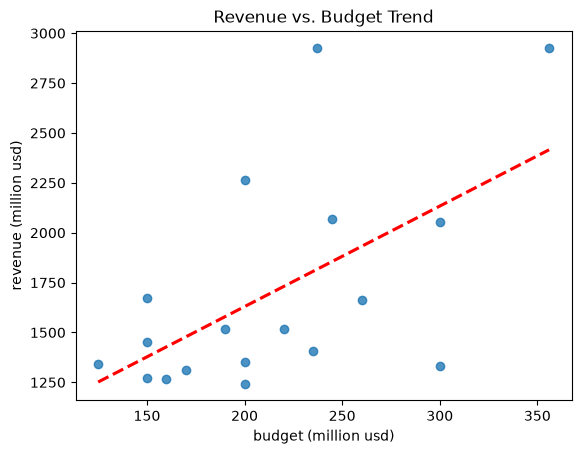

In [60]:
# Plots data and adds the trend line automatically
sns.regplot(x=x, y=y, ci=None, line_kws={"color": "red", "linestyle": "--"})
plt.title("Revenue vs. Budget Trend")
plt.show()

- ROI Distribution by Genre

In [61]:
genre_df = df.assign(genre_split=df["genres"].str.split("|")).explode("genre_split")
genre_df = pd.DataFrame(genre_df.groupby("genre_split")["ROI"].mean().sort_values(ascending=True))

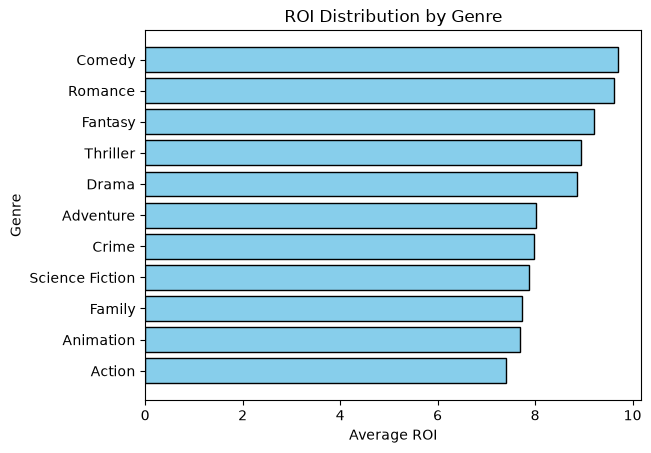

In [62]:
plt.barh(genre_df.index, genre_df["ROI"], color='skyblue', edgecolor='black')

# Add titles and labels
plt.title("ROI Distribution by Genre")
plt.xlabel("Average ROI")
plt.ylabel("Genre")

# Display the plot
plt.show()

- Popularity vs. Rating

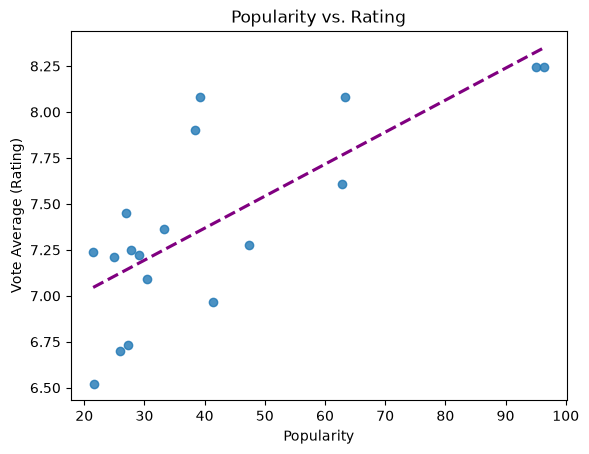

In [63]:
sns.regplot(x=df["popularity"], y=df["vote_average"], ci=None, line_kws={"color": "purple", "linestyle": "--"})
plt.title("Popularity vs. Rating")
plt.xlabel("Popularity")
plt.ylabel("Vote Average (Rating)")
plt.show()

- Yearly Trends in Box Office Performance

In [64]:
# Create dataframe that shows Revenue generated per year:
year_df = df.copy()
# Extract the release year
year_df["release_year"] = year_df["release_date"].dt.year
# Find revenue per year
year_revenue = (
    year_df.groupby("release_year")["revenue (million usd)"]
    .sum()
)

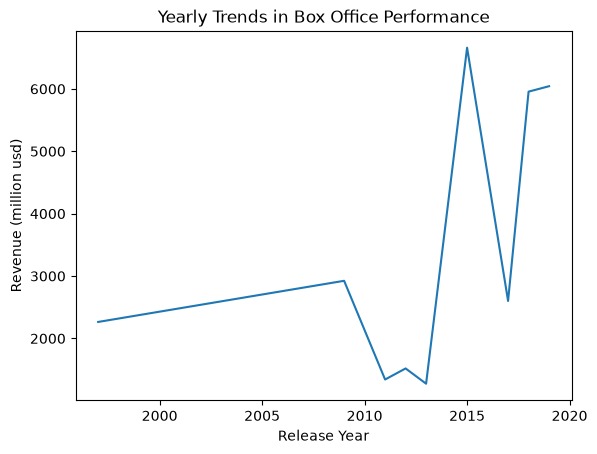

In [65]:
plt.plot(year_revenue.index, year_revenue.values)
plt.title("Yearly Trends in Box Office Performance")
plt.xlabel("Release Year")
plt.ylabel("Revenue (million usd)")
plt.show()

- Comparison of Franchise vs. Standalone Success

In [66]:
franchise_df = year_df.copy()
franchise_df["franchise"] = np.where(df["collection_name"].isna(), "Standalone", "Franchise")

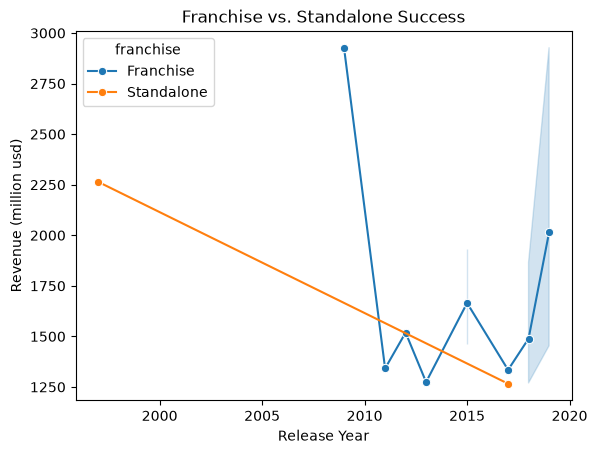

In [67]:
# Plot lines grouped by 'Franchise' using hue
sns.lineplot(data=franchise_df, x='release_year', y='revenue (million usd)', hue='franchise', marker='o')

# Add graph labels
plt.title("Franchise vs. Standalone Success")
plt.xlabel("Release Year")
plt.ylabel("Revenue (million usd)")
# plt.grid(True)

# Display the plot
plt.show()